# BERT による多義語の区別

BERT から文中の単語のベクトルを取り出し、多義語の意味を比較する実装です。英語の `bank` を「銀行」と「川岸」の意味で使う文を用意し、次の処理を実行します。

- 文脈に応じて変わる文脈化ベクトルを取り出す
- コサイン類似度で、同じ意味の文どうしと異なる意味の文どうしを比較する
- PCA（主成分分析）でベクトルを2次元に圧縮し、意味ごとの分布を可視化する

In [1]:
!pip install -q transformers  # BERT モデルの読み込み
!pip install -q torch  # ニューラルネットワークの計算基盤
!pip install -q numpy  # 数値計算（ベクトル演算）
!pip install -q matplotlib  # グラフの描画
!pip install -q japanize-matplotlib  # matplotlib のグラフを日本語表示にする
!pip install -q scikit-learn  # PCA による次元削減

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 31.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


## BERT を読み込む

Hugging Face の `transformers` から、英語の `bert-base-uncased` を読み込み、文中の各トークンに対応するベクトルを取り出します。

In [2]:
from transformers import AutoTokenizer, AutoModel

model_name = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(
    model_name,
    output_hidden_states=True,  # 最終層だけでなく全層の出力を取り出す（後半で使います）
)
model.eval()  # 推論モード（ドロップアウトなどを無効化）

print("BERT の読み込みが完了しました。")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT の読み込みが完了しました。


## 分析する文を用意する

多義語 `bank` を、2つの意味についてそれぞれいくつか文を用意します。
`"label"` は、`"financial"`（金融分野の「銀行」の意）か `"river"` （川の「土手」の意）かを表します。


In [3]:
bank_examples = [
{"text": "The central bank decided to raise interest rates again.", "label": "financial"},
{"text": "I went to the bank to deposit my paycheck yesterday afternoon.", "label": "financial"},
{"text": "She has been working as a teller at the local bank for five years.", "label": "financial"},
{"text": "My bank account is almost empty after paying all the bills.", "label": "financial"},
{"text": "The bank approved our mortgage application within a week.", "label": "financial"},
{"text": "Due to the economic crisis, a major bank collapsed.", "label": "financial"},
{"text": "You should check with your bank to see if they offer a better loan rate.", "label": "financial"},
{"text": "He robbed a bank and was sentenced to ten years in prison.", "label": "financial"},
{"text": "The investment bank reported record profits this quarter.", "label": "financial"},
{"text": "I lost my credit card and had to call the bank immediately to cancel it.", "label": "financial"},
{"text": "Online services provided by the bank have made managing my finances easier without visiting a physical branch.", "label": "financial"},
{"text": "The World Bank provides loans to developing countries for capital programs.", "label": "financial"},
{"text": "They took out a substantial loan from the bank to start their business.", "label": "financial"},
{"text": "The bank manager was very helpful in resolving my account issues.", "label": "financial"},
{"text": "You can transfer money between your bank accounts easily through the app.", "label": "financial"},
{"text": "Is there a bank near here where I can withdraw some cash?", "label": "financial"},
{"text": "The bank is closed on public holidays.", "label": "financial"},
{"text": "He kept all his savings in a piggy bank.", "label": "financial"},
{"text": "Many rural branches of the bank have been shut down recently.", "label": "financial"},
{"text": "The bank requires a valid ID before opening a new checking account.", "label": "financial"},
{"text": "The European Central Bank is headquartered in Frankfurt.", "label": "financial"},
{"text": "She stood in a long line at the bank just to cash a check.", "label": "financial"},
{"text": "The commercial bank offers favorable terms for small businesses.", "label": "financial"},
{"text": "I received an alert from my bank about suspicious activity on my card.", "label": "financial"},
{"text": "A foreign bank is struggling to gain market share in the country.", "label": "financial"},
{"text": "The bank teller greeted me with a warm smile.", "label": "financial"},
{"text": "After the scandal, the bank's stock price plummeted.", "label": "financial"},
{"text": "The bank teller carefully counted the thick stack of bills before handing it to the customer.", "label": "financial"},
{"text": "A digital-only bank is becoming increasingly popular among younger generations.", "label": "financial"},
{"text": "I need to stop by the bank to get some quarters for the laundromat.", "label": "financial"},
{"text": "The national bank plays a crucial role in regulating the country's monetary policy.", "label": "financial"},
{"text": "Her father is a prominent executive at a huge international bank.", "label": "financial"},
{"text": "We keep our most valuable documents in a safe deposit box at the bank.", "label": "financial"},
{"text": "The bank statement arrived in the mail today, detailing all the recent transactions.", "label": "financial"},
{"text": "If you fail to make your payments, the bank will foreclose on your home.", "label": "financial"},
{"text": "The bank vault can withstand explosions and extreme heat.", "label": "financial"},
{"text": "He was suspected of organizing a sophisticated bank fraud scheme.", "label": "financial"},
{"text": "Many people lost trust in the bank after the massive data breach.", "label": "financial"},
{"text": "The bank offers a loyalty program for customers who maintain a high balance.", "label": "financial"},
{"text": "To open a corporate bank account, you need to provide a lot of documentation.", "label": "financial"},
{"text": "The bank guarantees that your deposits are insured up to a certain amount.", "label": "financial"},
{"text": "I'm applying for a job as a financial analyst at a prestigious bank.", "label": "financial"},
{"text": "I want to the bank to deposity my money.", "label": "financial"},
{"text": "Our company uses a specific bank for all its payroll processing.", "label": "financial"},
{"text": "The bank's customer service hotline is available 24/7.", "label": "financial"},
{"text": "You will eventually need a co-signer if you have bad credit and want a loan from the bank.", "label": "financial"},
{"text": "The bank's new mobile app is very intuitive and user-friendly.", "label": "financial"},
{"text": "A run on the bank occurs when a large number of customers withdraw their deposits simultaneously.", "label": "financial"},
{"text": "The bank charges a hefty fee for international wire transfers.", "label": "financial"},
{"text": "She advised him not to put all his money in one bank.", "label": "financial"},
{"text": "They sat peacefully on the grassy river bank and watched the boats go by.", "label": "river"},
{"text": "The children had fun rolling down the steepest part of the grassy bank.", "label": "river"},
{"text": "Heavy rains caused the river to burst its bank, flooding the nearby town.", "label": "river"},
{"text": "We pitched our tent on the north bank of the stream.", "label": "river"},
{"text": "The dog leaped onto the muddy bank, shaking water all over us.", "label": "river"},
{"text": "Fishermen lined the bank, casting their lines into the dark water.", "label": "river"},
{"text": "Wildflowers grew abundantly along the sunny bank of the canal.", "label": "river"},
{"text": "The erosion of the river bank is a serious environmental concern.", "label": "river"},
{"text": "She walked slowly along the left bank of the Seine.", "label": "river"},
{"text": "The steep bank made it difficult to access the water safely.", "label": "river"},
{"text": "We found a perfect spot for a picnic on the wooded bank overlooking the lake.", "label": "river"},
{"text": "The boat gently bumped against the wooden dock near the sandy bank.", "label": "river"},
{"text": "A thick layer of mist rolled off the river and settled on the muddy bank.", "label": "river"},
{"text": "Rabbits had dug their burrows deep into the sandy bank.", "label": "river"},
{"text": "He carefully navigated the slippery bank to get closer to the waterfall.", "label": "river"},
{"text": "The city built a reinforced concrete bank to prevent future flooding damages.", "label": "river"},
{"text": "We sat on the rocky bank, skipping stones across the calm surface of the pond.", "label": "river"},
{"text": "The right bank of the river is mostly industrial, while the left is residential.", "label": "river"},
{"text": "We scrambled up the steep bank, pulling ourselves up using the exposed roots.", "label": "river"},
{"text": "Ducks were resting on the muddy bank beneath the willow tree.", "label": "river"},
{"text": "A small wooden bridge connected the opposite bank of the narrow gorge.", "label": "river"},
{"text": "The trail follows the winding bank of the creek for several miles.", "label": "river"},
{"text": "The floodwaters receded, leaving behind a thick layer of sludge on the river bank.", "label": "river"},
{"text": "They planted specific grasses to help stabilize the fragile bank.", "label": "river"},
{"text": "An old ruined castle stands on the opposite bank of the loch.", "label": "river"},
{"text": "The current carried the drifting log towards the shallow bank.", "label": "river"},
{"text": "He slipped on the wet moss covering the stone bank and fell into the freezing stream.", "label": "river"},
{"text": "Swallows build their nests in the side of the sandy bank.", "label": "river"},
{"text": "The moon illuminated the silhouettes of the trees on the far bank.", "label": "river"},
{"text": "They found an abandoned camp on the sheltered bank of the large river.", "label": "river"},
{"text": "The alligator slid silently from the muddy bank into the swamp.", "label": "river"},
{"text": "The snow had begun to melt, turning the bank into a slippery mess.", "label": "river"},
{"text": "You can get a beautiful view of the sunset from the eastern bank.", "label": "river"},
{"text": "The river bank was littered with debris after the severe storm passed.", "label": "river"},
{"text": "A heron stood motionless by the reedy bank, waiting for a fish.", "label": "river"},
{"text": "They rowed their boat across the lake and docked at the grassy bank.", "label": "river"},
{"text": "The local community organized a cleanup event along the river bank.", "label": "river"},
{"text": "She lay on her back on the soft mossy bank, staring up at the clouds.", "label": "river"},
{"text": "We decided to follow the bank downstream to see where it led.", "label": "river"},
{"text": "Huge boulders were dumped along the bank to create a makeshift sea wall.", "label": "river"},
{"text": "The path gradually ascends, following the steeply rising bank of the gorge.", "label": "river"},
{"text": "Otters were seen playing along the wooded bank earlier this morning.", "label": "river"},
{"text": "The artist set up his easel on the bank, painting the serene landscape.", "label": "river"},
{"text": "We heard a loud splash as something large plunged off the bank into the water.", "label": "river"},
{"text": "The children gathered smooth, flat stones from the gravel bank.", "label": "river"},
{"text": "The opposing armies faced each other from opposite bank of the river.", "label": "river"},
{"text": "Ferry service between the two sides of the river bank runs every hour.", "label": "river"},
{"text": "The car veered off the road and plunged down a steep bank.", "label": "river"},
{"text": "Dense fog obscured the opposite bank, making the river seem endless.", "label": "river"},
{"text": "They stood on the sandy bank, waving goodbye to the departing ship.", "label": "river"}
]

## 単語の文脈化ベクトルを取り出す

BERT に文を入力すると、各トークンに 768 次元のベクトル（周囲の単語の情報を取り込んだ**文脈化ベクトル**）が対応します。ここから、狙った単語（`bank`）に対応するベクトルだけを取り出す部品 `encode_word` を作ります。

引数 `layer` では、何層目の出力を取り出すかを選べます。既定の `-1` は最終層です（このあとの対照実験で `0`＝埋め込み層を使います）。

In [4]:
import numpy as np
import torch
from dataclasses import dataclass


def _find_subsequence(seq: list[int], sub: list[int]) -> int:
    """リスト seq の中で部分列 sub が最初に現れる開始位置を返す（なければ -1）。"""
    for i in range(len(seq) - len(sub) + 1):
        if seq[i : i + len(sub)] == sub:
            return i
    return -1

@dataclass
class BertEncoder:
    """BERT を保持し、文中の単語の文脈化ベクトルを取り出すエンコーダ。"""

    tokenizer: AutoTokenizer
    model: AutoModel

    def encode_word(self, text: str, word: str, layer: int = -1) -> np.ndarray:
        """文 text 中の単語 word に対応する、指定層のベクトルを返す（layer=-1 は最終層）。"""
        inputs = self.tokenizer(text, return_tensors="pt")
        with torch.no_grad():
            hidden_states = self.model(**inputs).hidden_states
        vectors = hidden_states[layer][0]  # (トークン数, 768)

        # word のトークン列が文中のどこにあるかを探し、その区間を平均する
        # add_special_tokens=False で [CLS]/[SEP] を付けず、探したい部分列だけを得る
        word_ids = self.tokenizer(word, add_special_tokens=False)["input_ids"]
        input_ids = inputs["input_ids"][0].tolist()
        start = _find_subsequence(input_ids, word_ids)
        assert start >= 0, f"'{word}' が文に見つかりません: {text}"
        return vectors[start : start + len(word_ids)].mean(dim=0).numpy()


encoder = BertEncoder(tokenizer=tokenizer, model=model)

# 動作確認：1文で bank のベクトルを取り出す
vec = encoder.encode_word(bank_examples[0]["text"], "bank")
print(f"ベクトルの次元: {vec.shape}")

ベクトルの次元: (768,)


1文から `bank` の 768 次元ベクトルが取り出せました。文すべてをベクトルに変換していきます。


## コサイン類似度を計算する

2つのベクトルの「向きの近さ」を測るのがコサイン類似度です。定義は次の通りで、値は $[-1, 1]$ の範囲に収まります。

$$\cos(\mathbf{a}, \mathbf{b}) = \frac{\mathbf{a} \cdot \mathbf{b}}{\|\mathbf{a}\|\,\|\mathbf{b}\|}$$

複数のベクトルをまとめて渡し、総当たりの類似度**行列**を返す関数を書きます。各ベクトルを長さ1に正規化してから内積を取れば、上の式と一致します。`@` は行列積、`.T` は行と列の入れ替えです。結果は数値の表で確かめます。

In [5]:
def cosine_similarity_matrix(vecs: np.ndarray) -> np.ndarray:
    """行ベクトル同士の総当たりコサイン類似度行列を返す。"""
    normed = vecs / np.linalg.norm(vecs, axis=1, keepdims=True)
    return normed @ normed.T


# 動作確認：銀行どうし・銀行と川岸で類似度を比べる

financial_examples = [e for e in bank_examples if e["label"] == "financial"]
river_examples = [e for e in bank_examples if e["label"] == "river"]

financial_vec_1 = encoder.encode_word(financial_examples[0]["text"], "bank")  # 銀行
financial_vec_2 = encoder.encode_word(financial_examples[1]["text"], "bank")  # 銀行
river_vec_1 = encoder.encode_word(river_examples[0]["text"], "bank")  # 川岸

sim = cosine_similarity_matrix(np.stack([financial_vec_1, financial_vec_2, river_vec_1]))
print(f"銀行 vs 銀行: {sim[0, 1]:.3f}")
print(f"銀行 vs 川岸: {sim[0, 2]:.3f}")

銀行 vs 銀行: 0.697
銀行 vs 川岸: 0.426


同じ意味の文どうしの方が、コサイン類似度が高くなっていることがわかります。

同じ `bank` という綴りなのに、文脈でベクトルが変わっていることが読み取れます。全文でこの傾向を確かめましょう。


In [6]:
# すべての文から bank の最終層ベクトルを抽出します
bank_vecs = np.stack([encoder.encode_word(ex["text"], "bank") for ex in bank_examples])

すべての文から、最終層の `bank` のベクトルを取り出しました。次に、これらを2次元に圧縮して分布を見ます。


## PCA でベクトルの分布を可視化する

768 次元は直接は眺められないので、PCA（主成分分析）で2次元に圧縮して散布図にします。銀行と川岸が別々のかたまりに分かれるでしょうか。


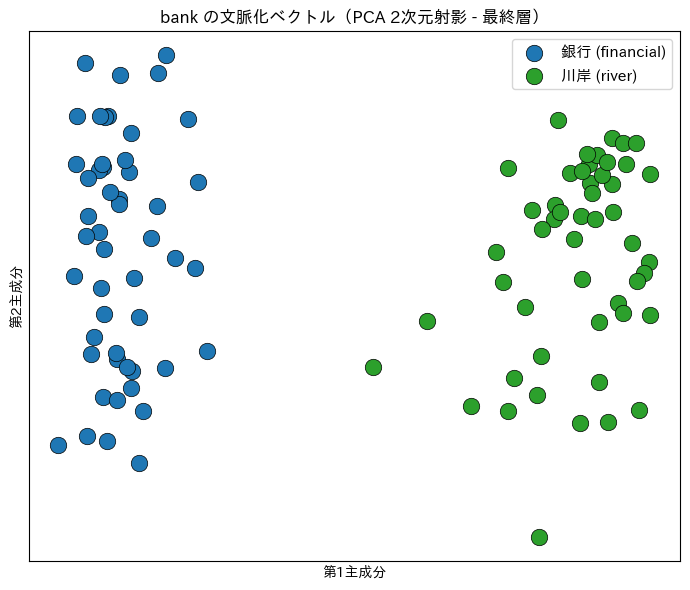

In [7]:
import matplotlib.pyplot as plt
import japanize_matplotlib
from sklearn.decomposition import PCA
import numpy as np

def plot_pca(vecs, labels, title, ax=None, show_legend=True, scatter_size=140):
    """与えられたベクトルをPCAで2次元に削減し、散布図としてプロットする共通関数。"""
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 6))

    coords = PCA(n_components=2, random_state=42).fit_transform(vecs)

    for sense, color in [("financial", "tab:blue"), ("river", "tab:green")]:
        idx = [i for i, label in enumerate(labels) if label == sense]
        label_name = "銀行 (financial)" if sense == "financial" else "川岸 (river)"
        ax.scatter(
            coords[idx, 0],
            coords[idx, 1],
            c=color,
            s=scatter_size,
            edgecolors="black",
            linewidth=0.5,
            label=label_name,
            zorder=5,
        )

    ax.set_title(title, fontsize=12)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.set_xticks([])
    ax.set_yticks([])
    if show_legend:
        ax.legend(fontsize=11)

# 最終層（12層目）のベクトルを共通関数を使って可視化
fig, ax = plt.subplots(figsize=(7, 6))
bank_labels = [ex["label"] for ex in bank_examples]
plot_pca(bank_vecs, bank_labels, "bank の文脈化ベクトル（PCA 2次元射影 - 最終層）", ax=ax, show_legend=True, scatter_size=140)
ax.set_xlabel("第1主成分")
ax.set_ylabel("第2主成分")
plt.tight_layout()
plt.show()

銀行（青）と川岸（緑）が別々のかたまりに分かれました。

数値と図の両方で、意味ごとの違いを確認できました。ただし PCA は線形な圧縮なので、高次元の構造をそのまま映しているわけではない点には注意してください。


## 層毎の違い

この違いが「文脈化」のおかげであることを確かめましょう。先ほどの結果は、最終層からの出力でしたが、それ以前の層も観察します。


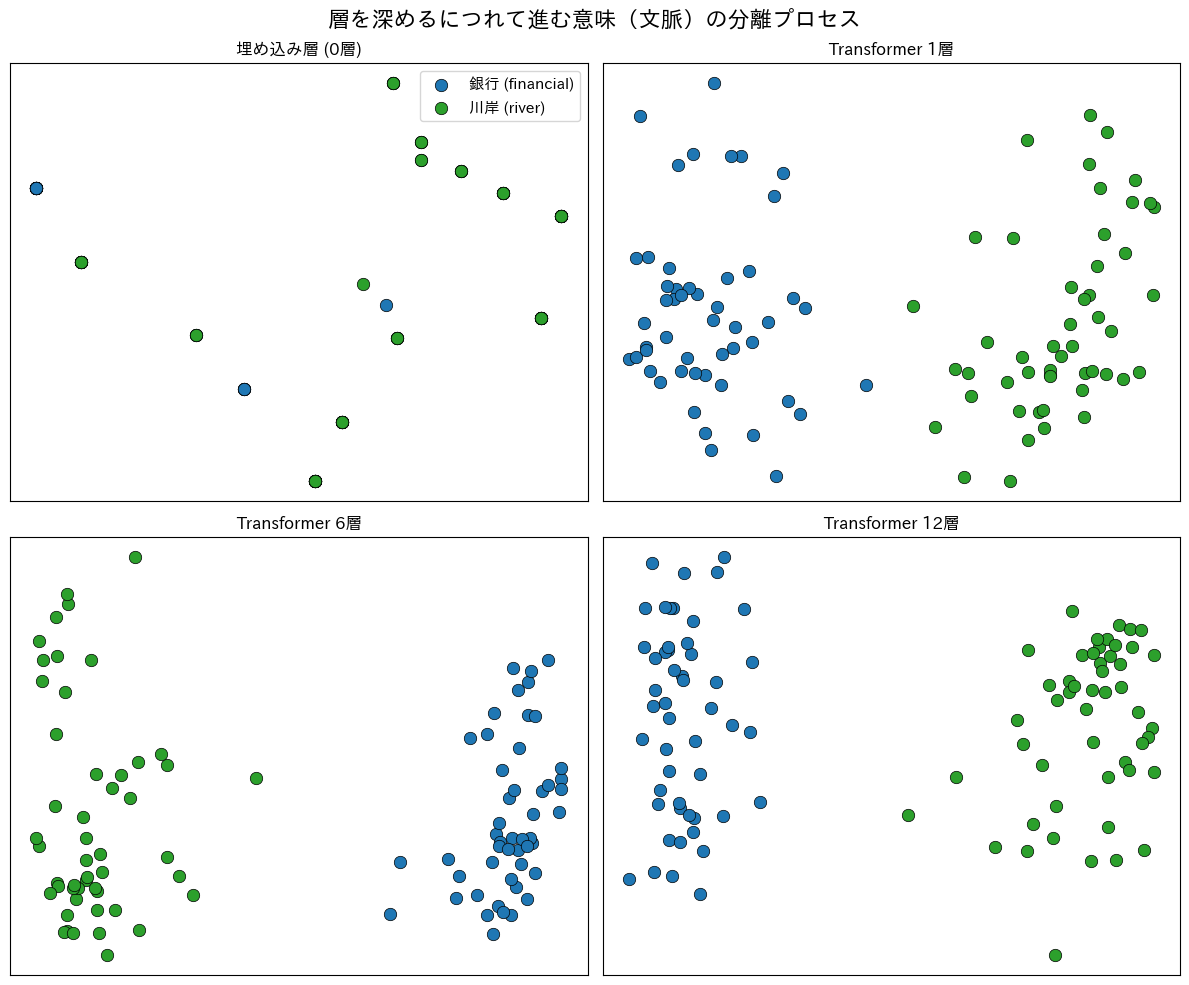

In [8]:
# 比較する層（0層:埋め込み, 1層:初期, 6層:中期, 12層:最終）
layers_to_compare = [0, 1, 6, 12]
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for idx, layer in enumerate(layers_to_compare):
    # 対象レイヤーのベクトルを抽出
    layer_vecs = np.stack([encoder.encode_word(ex["text"], "bank", layer=layer) for ex in bank_examples])

    # 共通関数 plot_pca を呼び出してプロット
    title_name = "埋め込み層 (0層)" if layer == 0 else f"Transformer {layer}層"
    plot_pca(
        vecs=layer_vecs,
        labels=bank_labels,
        title=title_name,
        ax=axes[idx],
        show_legend=(idx == 0),
        scatter_size=80
    )

plt.suptitle("層を深めるにつれて進む意味（文脈）の分離プロセス", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

0層目（埋め込み層）では、bank の単語埋め込み + 位置埋め込みのベクトルとなっているので、意味による違いというよりか、位置による違いによってベクトルが分布しています。


その後、１層目からすでに意味毎にベクトルが分かれていることがわかります。

## まとめ

この課題では、BERT の文脈化ベクトルが多義語の意味の違いを捉えられることを確かめました。

- 同じ `bank` でも、意味が同じ文どうしはコサイン類似度が高く、意味が違う文どうしは低くなりました。
- 埋め込み層（静的）では銀行と川岸を区別できず、区別は Transformer の文脈化によって生まれています。
- 意味の違いの表れ方は層によって変わります。

この性質は、語義曖昧性解消（文中の単語がどの意味で使われているかを判定するタスク）をはじめ、文脈に応じた意味理解が必要な下流タスクの土台になっています。


## 実験してみよう

手がかりの少ない短い文（例：`"The bank."`）を混ぜると、銀行と川岸のベクトルは区別できるでしょうか。また、銀行と河岸のどちらのクラスタからも離れた bank の文を作成できるでしょうか。
